# Review 4 + Review 8 — Kaggle folder-compatible evaluation (v3)

**Run this notebook with the two result folders already attached.** It now accepts **extracted folders OR ZIP archives**, even when Kaggle nests them under `/kaggle/input/datasets/...`.

- **With only the two result folders:** generates **Review 8 paired 20-patient Figure 5 and CSV**, then clearly marks distance-band and lesion-IoU analyses as **not run**.
- **With the original MS3SEG dataset also attached:** additionally computes **Review 4 ventricle-distance bands** and **Review 8 lesion IoU 0.10 / 0.25 / 0.50** from the ground-truth masks.

No model checkpoints, retraining, or GPU are needed. Do **not** report the skipped analyses as completed. If the dataset is missing, attach it in **Add Input** and rerun the same notebook. The original dataset must contain `MS_100_patient_preprocessed` and `MS_100_patient_masks`.

Distance bands use 3D physical spacing, not the paper's original 2D in-plane periventricular FP definition.

**Revision:** Includes prediction-file preflight checks and supports Kaggle-extracted result folders. This corrects the previous `patient_006` file-discovery failure and prints actual filenames when input contents are incomplete.


In [1]:
from pathlib import Path
import os, re, io, zipfile, json, gc, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
try:
    import nibabel as nib
except ImportError:
    nib = None
    print('NOTE: nibabel missing. If you attach original MS3SEG, run `%pip install nibabel` and restart.')

INPUT_ROOT = Path('/kaggle/input')
OUTPUT_ROOT = Path('/kaggle/working/VentiMorph_Review4_8')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
DATA_ROOT_OVERRIDE = None  # optional path to original MS3SEG root
VENTI_RESULTS_PATH = None  # optional path to VentiMorph result folder or ZIP
UNETPP_RESULTS_PATH = None  # optional path to U-Net++ result folder or ZIP
EXPECTED_TEST_IDS = ['006','008','014','024','027','033','036','040','041','042',
                     '046','055','057','071','074','076','079','085','088','100']
EXPECTED_SPLIT_SHA256 = 'd5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'
LABELS = {0:'background',1:'ventricle',2:'normal_wmh',3:'abnormal_wmh'}
print('Outputs:', OUTPUT_ROOT)

Outputs: /kaggle/working/VentiMorph_Review4_8


In [2]:
# Input diagnostics: display folders and the detected contents.
print('Kaggle input top-level folders:')
if INPUT_ROOT.exists():
    for p in sorted(INPUT_ROOT.iterdir()): print(' ',p)
else:
    print('  /kaggle/input is not present. Run this notebook on Kaggle.')
print('\nCandidate result folders (metadata + predictions):')
for p in sorted(INPUT_ROOT.rglob('final_locked_test_metadata.json')) if INPUT_ROOT.exists() else []:
    print(' ',p.parent)
print('\nCandidate result ZIPs:')
for p in sorted(INPUT_ROOT.rglob('*.zip')) if INPUT_ROOT.exists() else []:
    if 'LOCKED_TEST' in p.name.upper(): print(' ',p)
print('\nOriginal MRI dataset folders:')
for p in sorted(INPUT_ROOT.rglob('MS_100_patient_preprocessed')) if INPUT_ROOT.exists() else []:
    print(' ',p)
print('\nNote: If original MRI is not listed, the paired Figure 5 can still run, but distance and lesion IoU cannot.')

Kaggle input top-level folders:
  /kaggle/input/datasets

Candidate result folders (metadata + predictions):
  /kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_UNETPP_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS
  /kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS (1)

Candidate result ZIPs:

Original MRI dataset folders:
  /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG/MS_100_patient_preprocessed

Note: If original MRI is not listed, the paired Figure 5 can still run, but distance and lesion IoU cannot.


In [3]:
from contextlib import contextmanager

class FolderReader:
    # Exposes the small subset of ZipFile API used by the original analysis.
    def __init__(self, root):
        self.root = Path(root)
    def namelist(self):
        return [p.relative_to(self.root).as_posix() for p in self.root.rglob('*') if p.is_file()]
    def read(self, name):
        p=(self.root/name).resolve()
        if not p.is_relative_to(self.root.resolve()):
            raise ValueError('Unsafe relative result path')
        return p.read_bytes()
    def __enter__(self): return self
    def __exit__(self,*args): return False

@contextmanager
def open_results(path):
    path=Path(path)
    if path.is_dir():
        yield FolderReader(path)
    elif path.is_file() and path.suffix.lower()=='.zip':
        with zipfile.ZipFile(path) as z:
            yield z
    else:
        raise FileNotFoundError(f'Unsupported result source: {path}')

def valid_result_folder(p):
    return (p/'final_locked_test_metadata.json').is_file() and (p/'predictions').is_dir() and (p/'tables').is_dir()

def locate_results(model, override=None):
    if override is not None:
        p=Path(override)
        if not p.exists(): raise FileNotFoundError(f'{model}: override path does not exist: {p}')
        return p
    token=('V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS' if model=='VentiMorph'
           else 'UNETPP_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS')
    folders=[p.parent for p in INPUT_ROOT.rglob('final_locked_test_metadata.json')
             if token in str(p.parent).upper() and valid_result_folder(p.parent)]
    archives=[p for p in INPUT_ROOT.rglob('*.zip') if token in p.name.upper()]
    candidates=sorted(set(folders+archives),key=lambda p:(p.is_file(),len(p.parts),str(p)))
    if not candidates:
        # Robust fallback when Kaggle renames the containing folder.
        for p in INPUT_ROOT.rglob('final_locked_test_metadata.json'):
            if not valid_result_folder(p.parent): continue
            try:
                m=json.loads(p.read_text())
            except Exception:
                continue
            identity=m.get('model','').lower()
            if (model=='VentiMorph' and 'ventimorph' in identity) or (model=='UNetPP' and 'u-net++' in identity):
                candidates.append(p.parent)
    if not candidates:
        raise FileNotFoundError(f'{model}: could not find a locked-test result folder or ZIP in Kaggle Input. Attach it via Add Input.')
    if len(candidates)>1:
        print(f'NOTE: {model}: {len(candidates)} matching copies found. Using {candidates[0]}')
    return candidates[0]

def discover_data_root(override=None):
    if override:
        root=Path(override)
        if not ((root/'MS_100_patient_preprocessed').is_dir() and (root/'MS_100_patient_masks').is_dir()):
            raise FileNotFoundError(f'DATA_ROOT_OVERRIDE is not an MS3SEG root: {root}')
        return root
    pre=[p for p in INPUT_ROOT.rglob('*') if p.is_dir() and p.name.lower()=='ms_100_patient_preprocessed']
    valid=[]
    for p in pre:
        if any(x.is_dir() and x.name.lower()=='ms_100_patient_masks' for x in p.parent.iterdir()):
            valid.append(p.parent)
    valid=sorted(set(valid))
    if not valid:
        print('NOTICE: Original MS3SEG dataset is NOT attached. Review 4 and lesion IoU will be skipped.')
        return None
    if len(valid)>1:
        raise RuntimeError(f'Multiple MRI roots found: {valid}. Set DATA_ROOT_OVERRIDE explicitly.')
    return valid[0]

RESULT_PATHS={'VentiMorph':locate_results('VentiMorph',VENTI_RESULTS_PATH),
              'UNetPP':locate_results('UNetPP',UNETPP_RESULTS_PATH)}
DATA_ROOT=discover_data_root(DATA_ROOT_OVERRIDE)
HAS_GROUND_TRUTH=DATA_ROOT is not None
if HAS_GROUND_TRUTH and nib is None:
    raise ImportError('Original MS3SEG attached, but nibabel is missing. Run `%pip install nibabel`, restart and rerun.')
print('Results found:')
for k,p in RESULT_PATHS.items():print(' ',k,'->',p)
print('Original MS3SEG root:', DATA_ROOT or 'NOT ATTACHED — paired figure only')

def mask_root(kind):
    dirs=[p for p in (DATA_ROOT/'MS_100_patient_masks').iterdir() if p.is_dir()]
    if kind=='vent': hits=[p for p in dirs if 'vent' in p.name.lower()]
    elif kind=='nwmh': hits=[p for p in dirs if ('nwmh' in p.name.lower() or 'normal' in p.name.lower()) and 'abnormal' not in p.name.lower() and 'abwmh' not in p.name.lower()]
    else: hits=[p for p in dirs if ('abwmh' in p.name.lower() or 'abnormal' in p.name.lower())]
    if len(hits)!=1: raise RuntimeError(f'{kind}: ambiguous mask roots {hits}')
    return hits[0]
MASK_ROOTS={key:mask_root(key) for key in ('vent','nwmh','abwmh')} if DATA_ROOT is not None else {}

def unique_file(folder, patterns):
    hits=sorted(set(p for pat in patterns for p in folder.glob(pat) if p.is_file()))
    if len(hits)!=1: raise FileNotFoundError(f'Expected one file in {folder}, got {hits}')
    return hits[0]

def get_ground_truth(pid):
    paths={
        'vent':unique_file(MASK_ROOTS['vent']/pid,[f'{pid}_Vent_Mask.nii',f'{pid}_Vent_Mask.nii.gz','*Vent*Mask*.nii*']),
        'nwmh':unique_file(MASK_ROOTS['nwmh']/pid,[f'{pid}_nWMH_Mask.nii',f'{pid}_nWMH_Mask.nii.gz','*nWMH*Mask*.nii*']),
        'abwmh':unique_file(MASK_ROOTS['abwmh']/pid,[f'{pid}_abWMH_Mask.nii',f'{pid}_abWMH_Mask.nii.gz','*abWMH*Mask*.nii*']),
    }
    reference=unique_file(DATA_ROOT/'MS_100_patient_preprocessed'/pid,
                          [f'{pid}_FLAIR.nii',f'{pid}_FLAIR.nii.gz'])
    ref=nib.load(str(reference),mmap=True)
    target=np.zeros(ref.shape,dtype=np.uint8)
    for value,key in [(1,'vent'),(2,'nwmh'),(3,'abwmh')]:
        im=nib.load(str(paths[key]),mmap=True)
        if im.shape!=ref.shape or not np.allclose(im.affine,ref.affine,rtol=1e-4,atol=1e-3):
            raise ValueError(f'{pid}: {key} mask geometry mismatch; resampling must be justified, not silently applied.')
        target[np.asanyarray(im.dataobj)>0]=value # same class-overwrite order as original notebooks
    spacing=np.asarray(ref.header.get_zooms()[:3],dtype=float)
    if not (len(spacing)==3 and np.all(np.isfinite(spacing)) and np.all(spacing>0)):
        raise ValueError(f'{pid}: invalid spacing {spacing}')
    raw_vent=np.asanyarray(nib.load(str(paths['vent']),mmap=True).dataobj)>0
    return target,ref,spacing,raw_vent

def load_prediction(zf, pid, ref):
    """Load a patient NIfTI from a folder or ZIP, with clear failure diagnostics."""
    all_names = zf.namelist()
    nifti_names = [n for n in all_names if n.lower().endswith(('.nii.gz', '.nii'))]
    # Match the exact patient ID as a filename token (not a substring of another ID).
    matches = [n for n in nifti_names if re.search(
        rf'(?:^|/)patient[_-]?{re.escape(pid)}(?:[_-]|\.)', n, flags=re.IGNORECASE
    ) and 'ensemble_prediction' in Path(n).name.lower()]
    if len(matches) != 1:
        sample = nifti_names[:30] if nifti_names else all_names[:30]
        raise RuntimeError(
            f'{pid}: expected one saved ensemble prediction NIfTI, found {len(matches)}. '
            f'Candidate matches={matches[:10]}; total NIfTI files={len(nifti_names)}; '
            f'first available entries={sample}.\n'
            'If total NIfTI files is zero, Kaggle has not provided the actual '
            'prediction files: attach/re-upload the COMPLETE result folders '
            '(including their predictions/*.nii.gz files).'
        )
    name = matches[0]
    data = zf.read(name)
    if name.lower().endswith('.nii.gz'):
        import gzip
        data = gzip.decompress(data)
    image = nib.Nifti1Image.from_bytes(data)
    if image.shape != ref.shape or not np.allclose(image.affine, ref.affine, rtol=1e-4, atol=1e-3):
        raise ValueError(f'{pid}: prediction geometry differs from original FLAIR; '
                         f'prediction shape={image.shape}, MRI shape={ref.shape}.')
    pred = np.asanyarray(image.dataobj).astype(np.uint8)
    if not np.isin(np.unique(pred), [0, 1, 2, 3]).all():
        raise ValueError(f'{pid}: unexpected label values {np.unique(pred)}')
    return pred

def patient_metric_tables(zf):
    matches=[n for n in zf.namelist() if n.endswith('tables/v281_locked_test_patient_metrics.csv')]
    if len(matches)!=1: raise RuntimeError(f'Missing patient metrics CSV: {matches}')
    df=pd.read_csv(io.BytesIO(zf.read(matches[0])),dtype={'patient_id':str})
    df['patient_id']=df['patient_id'].str.zfill(3)
    if set(df.patient_id)!=set(EXPECTED_TEST_IDS) or len(df)!=20:
        raise ValueError('Result archive does not contain the expected frozen 20 patients')
    return df

with open_results(RESULT_PATHS['VentiMorph']) as z:
    venti_metrics=patient_metric_tables(z)
with open_results(RESULT_PATHS['UNetPP']) as z:
    unetpp_metrics=patient_metric_tables(z)
# Verify frozen split, model identity and five-member ensemble from the saved evaluation metadata.
for model,path in RESULT_PATHS.items():
    with open_results(path) as z:
        meta=json.loads(z.read('final_locked_test_metadata.json'))
    if meta.get('split_sha256')!=EXPECTED_SPLIT_SHA256 or meta.get('ensemble_members')!=5:
        raise RuntimeError(f'{model}: split/ensemble metadata mismatch: {meta}')
    print(model,'split SHA256 and five-member ensemble verified')
print('Both result ZIPs contain the same locked 20 patients.')

Results found:
  VentiMorph -> /kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS (1)
  UNetPP -> /kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_UNETPP_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS
Original MS3SEG root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
VentiMorph split SHA256 and five-member ensemble verified
UNetPP split SHA256 and five-member ensemble verified
Both result ZIPs contain the same locked 20 patients.


## Review 8 — Full-precision paired Figure 5

Uses the **saved** patient-level Dice CSVs; no MRI data is needed for this cell. The patient IDs are aligned explicitly, never by row order.

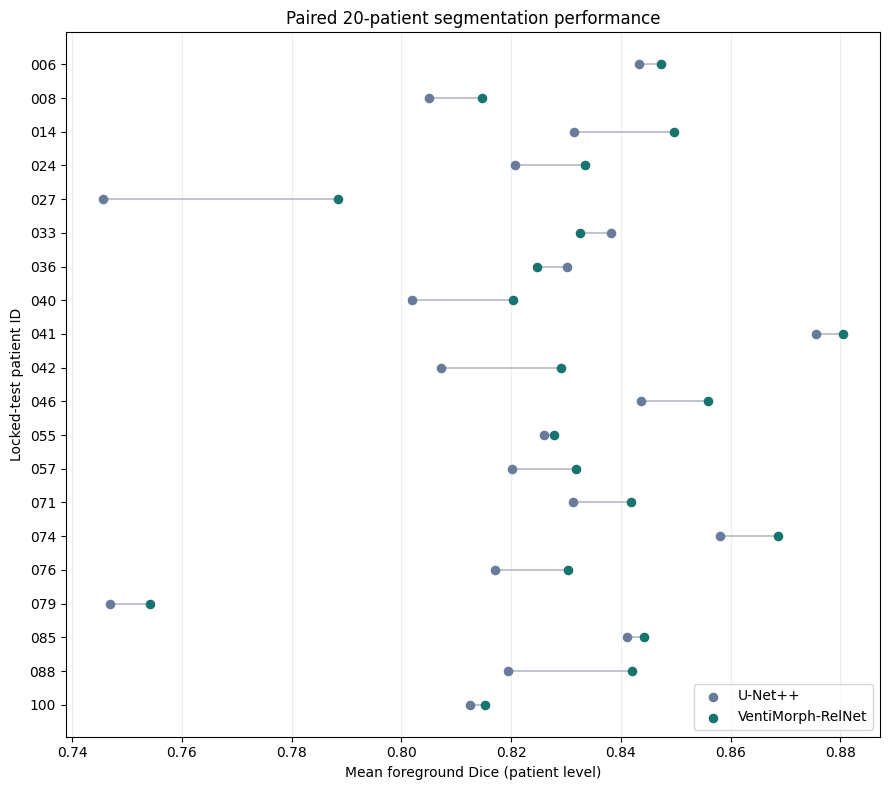

VentiMorph mean: 0.8316663911262893
U-Net++ mean: 0.8207676705889622
Mean paired difference: 0.01089872053732716
VentiMorph better in: 18 of 20 patients


In [4]:
paired=venti_metrics[['patient_id','mean_foreground_dice']].rename(columns={'mean_foreground_dice':'ventimorph_dice'}).merge(
    unetpp_metrics[['patient_id','mean_foreground_dice']].rename(columns={'mean_foreground_dice':'unetpp_dice'}),
    on='patient_id',validate='one_to_one').sort_values('patient_id')
paired['dice_delta']=paired['ventimorph_dice']-paired['unetpp_dice']
paired.to_csv(OUTPUT_ROOT/'Review8_paired_20_patient_full_precision.csv',index=False)

fig,ax=plt.subplots(figsize=(9,8))
y=np.arange(len(paired))
for i,(_,r) in enumerate(paired.iterrows()):
    ax.plot([r.unetpp_dice,r.ventimorph_dice],[i,i],color='#b4b9c3',lw=1.2,zorder=1)
ax.scatter(paired.unetpp_dice,y,label='U-Net++',color='#687b9b',s=35,zorder=3)
ax.scatter(paired.ventimorph_dice,y,label='VentiMorph-RelNet',color='#18746e',s=35,zorder=3)
ax.set_yticks(y,paired.patient_id)
ax.invert_yaxis()
ax.set_xlabel('Mean foreground Dice (patient level)')
ax.set_ylabel('Locked-test patient ID')
ax.set_title('Paired 20-patient segmentation performance')
ax.grid(axis='x',alpha=.22)
ax.legend(loc='lower right')
fig.tight_layout()
for ext in ['png','pdf']:
    fig.savefig(OUTPUT_ROOT/f'Figure5_Paired_20_Patients.{ext}',dpi=300,bbox_inches='tight')
plt.show()
print('VentiMorph mean:',paired.ventimorph_dice.mean())
print('U-Net++ mean:',paired.unetpp_dice.mean())
print('Mean paired difference:',paired.dice_delta.mean())
print('VentiMorph better in:',int((paired.dice_delta>0).sum()),'of',len(paired),'patients')

## Review 4 — Distance-to-ventricle error analysis

Distance bands are defined from the **true ventricle mask** using 3D Euclidean distance with physical `(x,y,z)` spacing. Voxels *inside* the ventricle are excluded. We calculate **normal and abnormal WMH Dice, FP per 1,000 negative voxels, FP among predictions, and class confusion** separately in each band. When neither truth nor prediction contains a class in a band, Dice is **NaN** (not artificially 1.0). Results include patient-macro and pooled counts.

In [5]:
# Verify all 20 prediction files are visible BEFORE expensive MRI analysis.
# This prevents a late failure after successfully attaching MS3SEG.
for model, result_path in RESULT_PATHS.items():
    with open_results(result_path) as reader:
        names = reader.namelist()
        nifti = [n for n in names if n.lower().endswith(('.nii.gz', '.nii'))]
        print(f'{model}: {len(nifti)} NIfTI prediction files; example names: {nifti[:3]}')
        missing = [pid for pid in EXPECTED_TEST_IDS if not any(
            re.search(rf'(?:^|/)patient[_-]?{re.escape(pid)}(?:[_-]|\.)', n, flags=re.IGNORECASE)
            and 'ensemble_prediction' in Path(n).name.lower() for n in nifti)]
        if missing:
            print(f'WARNING: {model} predictions unavailable for patients: {missing}')
            print('Please attach the COMPLETE prediction result files to this notebook.')
            raise FileNotFoundError(f'{model}: {len(missing)} saved patient prediction files missing; '
                                    f'available file sample: {names[:20]}')
print('All 40 patient prediction files found. Proceeding with Review 4 and Review 8.')


VentiMorph: 20 NIfTI prediction files; example names: ['predictions/patient_014_v281_ensemble_prediction.nii', 'predictions/patient_100_v281_ensemble_prediction.nii', 'predictions/patient_071_v281_ensemble_prediction.nii']
UNetPP: 20 NIfTI prediction files; example names: ['predictions/patient_014_v281_ensemble_prediction.nii', 'predictions/patient_100_v281_ensemble_prediction.nii', 'predictions/patient_071_v281_ensemble_prediction.nii']
All 40 patient prediction files found. Proceeding with Review 4 and Review 8.


In [6]:
if HAS_GROUND_TRUTH:
    BANDS=[('0-3mm',0.0,3.0),('3-10mm',3.0,10.0),('>10mm',10.0,np.inf)]

    def distance_band_metrics(pred,truth,spacing,patient_id,model,vent):
        # Use the original ventricle mask, not the composed label (which may be overwritten by WMH).
        vent=vent.astype(bool)
        # 3D EDT: the distances are in mm, including through-plane spacing.
        dist=ndimage.distance_transform_edt(~vent,sampling=tuple(spacing))
        rows=[]
        for band,lo,hi in BANDS:
            region=(~vent)&(dist>lo)&(dist<=hi)
            for cls in (2,3):
                positive=(truth==cls)&region
                proposed=(pred==cls)&region
                tp=int((positive&proposed).sum());fp=int((~positive&proposed).sum());fn=int((positive&~proposed).sum())
                negatives=int(region.sum())-int(positive.sum())
                dice=2*tp/(2*tp+fp+fn) if (2*tp+fp+fn)>0 else np.nan
                rows.append(dict(model=model,patient_id=patient_id,band=band,class_name=LABELS[cls],
                    spacing_x_mm=float(spacing[0]),spacing_y_mm=float(spacing[1]),spacing_z_mm=float(spacing[2]),
                    band_voxels=int(region.sum()),truth_voxels=int(positive.sum()),pred_voxels=int(proposed.sum()),
                    tp=tp,fp=fp,fn=fn,negatives=negatives,dice=dice,
                    fp_per_1000_negative_voxels=(1000*fp/negatives if negatives else np.nan),
                    fp_fraction_of_predicted=(fp/int(proposed.sum()) if proposed.any() else np.nan),
                    to_background=int((positive&(pred==0)).sum()),
                    swapped_to_other_wmh=int((positive&(pred==(3 if cls==2 else 2))).sum()),
                    swap_rate=(int((positive&(pred==(3 if cls==2 else 2))).sum())/int(positive.sum()) if positive.any() else np.nan),
                    background_miss_rate=(int((positive&(pred==0)).sum())/int(positive.sum()) if positive.any() else np.nan)))
        return rows

    band_rows=[]; conf_rows=[]; iou_rows=[]; validation_rows=[]
    for model,zip_path in RESULT_PATHS.items():
        with open_results(zip_path) as zf:
            saved=patient_metric_tables(zf).set_index('patient_id')
            for k,pid in enumerate(EXPECTED_TEST_IDS,1):
                truth,ref,spacing,true_vent=get_ground_truth(pid)
                pred=load_prediction(zf,pid,ref)
                band_rows.extend(distance_band_metrics(pred,truth,spacing,pid,model,true_vent))
                conf=np.bincount((truth.astype(np.int64)*4+pred).ravel(),minlength=16).reshape(4,4)
                for a in (2,3):
                    for b in (0,2,3):
                        if a==b:continue
                        conf_rows.append(dict(model=model,patient_id=pid,true_class=LABELS[a],predicted_class=LABELS[b],
                                              count=int(conf[a,b]),total_true=int(conf[a].sum()),
                                              fraction=(conf[a,b]/conf[a].sum() if conf[a].sum() else np.nan)))
                dice=[]
                for cls in (1,2,3):
                    a=pred==cls;b=truth==cls
                    den=int(a.sum()+b.sum())
                    dice.append((2*int((a&b).sum())/den) if den else 1.0)
                computed=float(np.mean(dice))
                reference=float(saved.loc[pid,'mean_foreground_dice'])
                if abs(computed-reference)>2e-5:
                    raise AssertionError(f'{model} patient {pid}: saved Dice {reference:.7f} != recomputed {computed:.7f}. Check data/labels.')
                validation_rows.append(dict(model=model,patient_id=pid,recomputed_dice=computed,saved_dice=reference))
                # Lesion IoU functions defined in next cell; the mask/pred are loaded again there to keep the logic independent.
                print(f'{model} {k:02d}/20 patient {pid}: Dice verified {computed:.4f}')
                del truth,pred,ref,conf,true_vent
                gc.collect()

    band_df=pd.DataFrame(band_rows)
    conf_df=pd.DataFrame(conf_rows)
    validation_df=pd.DataFrame(validation_rows)
    band_df.to_csv(OUTPUT_ROOT/'Review4_distance_bands_per_patient.csv',index=False)
    conf_df.to_csv(OUTPUT_ROOT/'Review4_normal_abnormal_confusion_per_patient.csv',index=False)
    validation_df.to_csv(OUTPUT_ROOT/'Review4_saved_Dice_recomputation_check.csv',index=False)

    # Patient-macro results: means of patient-wise ratios (not the same as global pooled voxel metrics).
    macro=band_df.groupby(['model','band','class_name'],observed=True).agg(
        patients=('patient_id','nunique'),valid_dice_patients=('dice','count'),
        mean_patient_dice=('dice','mean'),sd_patient_dice=('dice','std'),
        mean_fp_per_1000=('fp_per_1000_negative_voxels','mean'),
        mean_fp_fraction=('fp_fraction_of_predicted','mean'),
        total_tp=('tp','sum'),total_fp=('fp','sum'),total_fn=('fn','sum'),
        total_negatives=('negatives','sum'),total_true=('truth_voxels','sum'),
        total_swaps=('swapped_to_other_wmh','sum'),total_background_misses=('to_background','sum'),
        mean_swap_rate=('swap_rate','mean'),mean_background_miss_rate=('background_miss_rate','mean')).reset_index()
    macro['pooled_dice']=2*macro.total_tp/(2*macro.total_tp+macro.total_fp+macro.total_fn).replace(0,np.nan)
    macro['pooled_fp_per_1000']=1000*macro.total_fp/macro.total_negatives.replace(0,np.nan)
    macro['pooled_swap_rate']=macro.total_swaps/macro.total_true.replace(0,np.nan)
    macro['pooled_background_miss_rate']=macro.total_background_misses/macro.total_true.replace(0,np.nan)
    macro.to_csv(OUTPUT_ROOT/'Review4_distance_band_summary.csv',index=False)
    display(macro[['model','band','class_name','valid_dice_patients','mean_patient_dice','mean_fp_per_1000','pooled_dice','pooled_fp_per_1000']])
else:
    print("SKIPPED: requires the original MS3SEG MRI + ground-truth masks. Attach MS3SEG in Kaggle Add Input and rerun.")

VentiMorph 01/20 patient 006: Dice verified 0.8474
VentiMorph 02/20 patient 008: Dice verified 0.8148
VentiMorph 03/20 patient 014: Dice verified 0.8496
VentiMorph 04/20 patient 024: Dice verified 0.8335
VentiMorph 05/20 patient 027: Dice verified 0.7884
VentiMorph 06/20 patient 033: Dice verified 0.8326
VentiMorph 07/20 patient 036: Dice verified 0.8247
VentiMorph 08/20 patient 040: Dice verified 0.8204
VentiMorph 09/20 patient 041: Dice verified 0.8805
VentiMorph 10/20 patient 042: Dice verified 0.8291
VentiMorph 11/20 patient 046: Dice verified 0.8559
VentiMorph 12/20 patient 055: Dice verified 0.8279
VentiMorph 13/20 patient 057: Dice verified 0.8319
VentiMorph 14/20 patient 071: Dice verified 0.8418
VentiMorph 15/20 patient 074: Dice verified 0.8687
VentiMorph 16/20 patient 076: Dice verified 0.8303
VentiMorph 17/20 patient 079: Dice verified 0.7542
VentiMorph 18/20 patient 085: Dice verified 0.8443
VentiMorph 19/20 patient 088: Dice verified 0.8421
VentiMorph 20/20 patient 100: D

,model,band,class_name,valid_dice_patients,mean_patient_dice,mean_fp_per_1000,pooled_dice,pooled_fp_per_1000
0,UNetPP,0-3mm,abnormal_wmh,20,0.620447,6.682273,0.679011,6.639323
1,UNetPP,0-3mm,normal_wmh,20,0.783857,75.068450,0.787579,74.576271
2,UNetPP,3-10mm,abnormal_wmh,20,0.813380,5.690750,0.840917,5.721436
3,UNetPP,3-10mm,normal_wmh,20,0.475889,2.251974,0.490754,2.197226
4,UNetPP,>10mm,abnormal_wmh,20,0.785461,0.119937,0.822980,0.119591
5,UNetPP,>10mm,normal_wmh,16,0.438881,0.015154,0.643414,0.015181
6,VentiMorph,0-3mm,abnormal_wmh,20,0.652978,7.567441,0.717595,7.357088
7,VentiMorph,0-3mm,normal_wmh,20,0.788218,72.230570,0.792737,71.666232
8,VentiMorph,3-10mm,abnormal_wmh,20,0.834021,5.920247,0.856191,5.867671
9,VentiMorph,3-10mm,normal_wmh,20,0.510104,1.945285,0.537287,1.917550


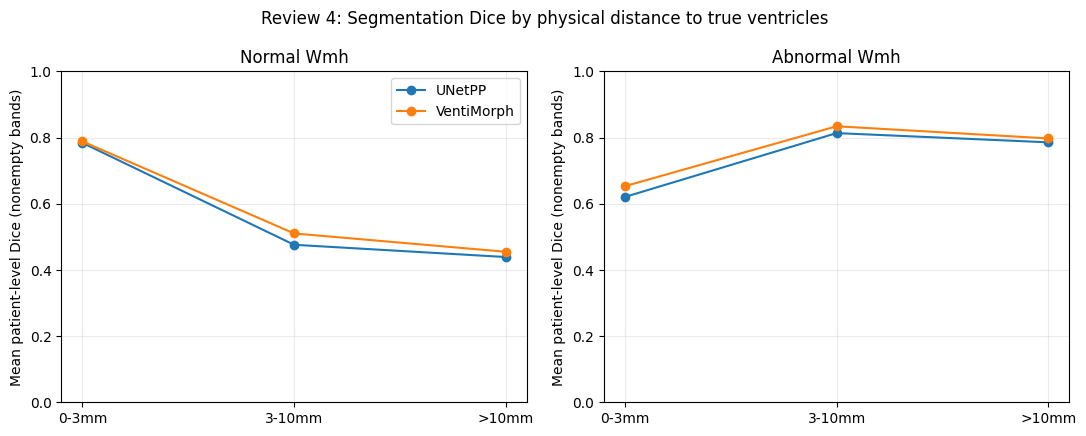

In [7]:
if HAS_GROUND_TRUTH:
    # Paired model differences in each distance band, preserving patient identity.
    wide=band_df.pivot(index=['patient_id','band','class_name'],columns='model',values=['dice','fp_per_1000_negative_voxels'])
    wide.columns=[f'{metric}_{model}' for metric,model in wide.columns]
    wide=wide.reset_index()
    wide['dice_delta_VentiMorph_minus_UNetPP']=wide['dice_VentiMorph']-wide['dice_UNetPP']
    wide['fp_density_delta_VentiMorph_minus_UNetPP']=(wide['fp_per_1000_negative_voxels_VentiMorph']-
                                                     wide['fp_per_1000_negative_voxels_UNetPP'])
    wide.to_csv(OUTPUT_ROOT/'Review4_paired_distance_band_differences.csv',index=False)

    fig,axes=plt.subplots(1,2,figsize=(11,4.4))
    order=[x[0] for x in BANDS]
    for ax,cls in zip(axes,['normal_wmh','abnormal_wmh']):
        for model in ['UNetPP','VentiMorph']:
            sub=macro[(macro.class_name==cls)&(macro.model==model)].set_index('band').reindex(order)
            ax.plot(order,sub.mean_patient_dice,marker='o',label=model)
        ax.set_title(cls.replace('_',' ').title())
        ax.set_ylabel('Mean patient-level Dice (nonempty bands)')
        ax.set_ylim(0,1)
        ax.grid(alpha=.25)
    axes[0].legend()
    fig.suptitle('Review 4: Segmentation Dice by physical distance to true ventricles')
    fig.tight_layout()
    for ext in ['png','pdf']:
        fig.savefig(OUTPUT_ROOT/f'Review4_distance_band_Dice.{ext}',dpi=300,bbox_inches='tight')
    plt.show()
else:
    print("SKIPPED: requires the original MS3SEG MRI + ground-truth masks. Attach MS3SEG in Kaggle Add Input and rerun.")

## Review 8 — Lesion detection at three IoU thresholds

Exact original choices: 3D **18-connected components**, **minimum 3 voxels**, IoU matching via **Hungarian maximum-total-IoU assignment**, and the original empty-mask convention (both empty ⇒ F1=1). The **same** components are used for all thresholds. The table reports per-patient macro means and pooled TP/FP/FN for normal and abnormal WMH. This is a sensitivity analysis of the *fixed* predictions, not test-set threshold selection.

In [8]:
if HAS_GROUND_TRUTH:
    def label_components(mask,minimum_voxels=3):
        structure=ndimage.generate_binary_structure(3,2)  # original notebook: 18 connectivity
        labels,num=ndimage.label(mask.astype(bool),structure=structure)
        counts=np.bincount(labels.ravel(),minlength=num+1)
        keep=np.where(counts>=minimum_voxels)[0]
        keep=keep[keep!=0]
        # Compact IDs 1..N. Use original labels only for overlap lookup.
        return labels,keep,counts

    def lesion_matching_all_thresholds(pred,truth,thresholds=(.10,.25,.50),minimum_voxels=3):
        lp,kp,cp=label_components(pred,minimum_voxels)
        lt,kt,ct=label_components(truth,minimum_voxels)
        npred=len(kp);ntrue=len(kt)
        iou=np.zeros((ntrue,npred),dtype=np.float64)
        if npred and ntrue:
            # Compute only pairs sharing voxels, without materializing a full-volume boolean mask per lesion.
            overlap=(lt>0)&(lp>0)
            if overlap.any():
                pairs=np.stack([lt[overlap],lp[overlap]],axis=1)
                pair_ids,pair_counts=np.unique(pairs,axis=0,return_counts=True)
                rmap={int(v):i for i,v in enumerate(kt)};cmap={int(v):j for j,v in enumerate(kp)}
                for (a,b),inter in zip(pair_ids,pair_counts):
                    ai=rmap.get(int(a));bj=cmap.get(int(b))
                    if ai is not None and bj is not None:
                        iou[ai,bj]=int(inter)/(int(ct[a])+int(cp[b])-int(inter))
            ri,ci=linear_sum_assignment(-iou) # matches original method
            assigned=iou[ri,ci]
        else:
            assigned=np.array([],dtype=float)
        result=[]
        for threshold in thresholds:
            if ntrue==0 and npred==0:
                tp=fp=fn=0;precision=recall=f1=1.0
            else:
                tp=int((assigned>=threshold).sum())
                fp=npred-tp;fn=ntrue-tp
                recall=tp/ntrue if ntrue else 1.0
                precision=tp/npred if npred else (1.0 if ntrue==0 else 0.0)
                f1=(2*precision*recall/(precision+recall)) if precision+recall else 0.0
            result.append(dict(iou_threshold=float(threshold),true_lesions=ntrue,predicted_lesions=npred,
                               matched_lesions=tp,false_positive_lesions=fp,false_negative_lesions=fn,
                               lesion_precision=precision,lesion_recall=recall,lesion_f1=f1))
        return result

    # Tiny correctness checks, including empty-mask and a perfect 3-voxel lesion.
    t=np.zeros((8,8,5),bool);t[2:5,2,2]=True
    assert all(abs(r['lesion_f1']-1)<1e-12 for r in lesion_matching_all_thresholds(t,t))
    assert all(abs(r['lesion_f1']-1)<1e-12 for r in lesion_matching_all_thresholds(np.zeros_like(t),np.zeros_like(t)))

    lesion_rows=[]
    for model,zip_path in RESULT_PATHS.items():
        with open_results(zip_path) as zf:
            for k,pid in enumerate(EXPECTED_TEST_IDS,1):
                truth,ref,spacing,true_vent=get_ground_truth(pid)
                pred=load_prediction(zf,pid,ref)
                for cls in (2,3):
                    for r in lesion_matching_all_thresholds(pred==cls,truth==cls):
                        lesion_rows.append(dict(model=model,patient_id=pid,class_name=LABELS[cls],**r))
                print(f'{model} {k:02d}/20 patient {pid}: lesion matching complete')
                del truth,pred,ref,true_vent
                gc.collect()
    lesion_df=pd.DataFrame(lesion_rows)
    lesion_df.to_csv(OUTPUT_ROOT/'Review8_lesion_IoU_per_patient.csv',index=False)
    lesion_summary=lesion_df.groupby(['model','class_name','iou_threshold']).agg(
        patients=('patient_id','nunique'),mean_lesion_f1=('lesion_f1','mean'),sd_lesion_f1=('lesion_f1','std'),
        mean_lesion_precision=('lesion_precision','mean'),mean_lesion_recall=('lesion_recall','mean'),
        total_matched=('matched_lesions','sum'),total_predicted=('predicted_lesions','sum'),
        total_true=('true_lesions','sum')).reset_index()
    lesion_summary['pooled_lesion_f1']=2*lesion_summary.total_matched/(lesion_summary.total_predicted+lesion_summary.total_true).replace(0,np.nan)
    lesion_summary.to_csv(OUTPUT_ROOT/'Review8_lesion_IoU_summary.csv',index=False)
    display(lesion_summary)
else:
    print("SKIPPED: requires the original MS3SEG MRI + ground-truth masks. Attach MS3SEG in Kaggle Add Input and rerun.")

VentiMorph 01/20 patient 006: lesion matching complete
VentiMorph 02/20 patient 008: lesion matching complete
VentiMorph 03/20 patient 014: lesion matching complete
VentiMorph 04/20 patient 024: lesion matching complete
VentiMorph 05/20 patient 027: lesion matching complete
VentiMorph 06/20 patient 033: lesion matching complete
VentiMorph 07/20 patient 036: lesion matching complete
VentiMorph 08/20 patient 040: lesion matching complete
VentiMorph 09/20 patient 041: lesion matching complete
VentiMorph 10/20 patient 042: lesion matching complete
VentiMorph 11/20 patient 046: lesion matching complete
VentiMorph 12/20 patient 055: lesion matching complete
VentiMorph 13/20 patient 057: lesion matching complete
VentiMorph 14/20 patient 071: lesion matching complete
VentiMorph 15/20 patient 074: lesion matching complete
VentiMorph 16/20 patient 076: lesion matching complete
VentiMorph 17/20 patient 079: lesion matching complete
VentiMorph 18/20 patient 085: lesion matching complete
VentiMorph

,model,class_name,iou_threshold,patients,mean_lesion_f1,sd_lesion_f1,mean_lesion_precision,mean_lesion_recall,total_matched,total_predicted,total_true,pooled_lesion_f1
0,UNetPP,abnormal_wmh,0.10,20,0.769419,0.069793,0.792894,0.754826,567,727,753,0.766216
1,UNetPP,abnormal_wmh,0.25,20,0.747518,0.078705,0.771029,0.732688,549,727,753,0.741892
2,UNetPP,abnormal_wmh,0.50,20,0.617231,0.102705,0.634538,0.606796,459,727,753,0.620270
3,UNetPP,normal_wmh,0.10,20,0.614069,0.100850,0.658651,0.580351,392,592,677,0.617809
4,UNetPP,normal_wmh,0.25,20,0.551691,0.103175,0.591345,0.521824,353,592,677,0.556344
5,UNetPP,normal_wmh,0.50,20,0.325761,0.115971,0.348229,0.309014,208,592,677,0.327817
6,VentiMorph,abnormal_wmh,0.10,20,0.792691,0.064397,0.824005,0.771602,580,719,753,0.788043
7,VentiMorph,abnormal_wmh,0.25,20,0.766534,0.076558,0.797730,0.745457,561,719,753,0.762228
8,VentiMorph,abnormal_wmh,0.50,20,0.661937,0.106010,0.688864,0.643863,486,719,753,0.660326
9,VentiMorph,normal_wmh,0.10,20,0.617073,0.093861,0.653111,0.596084,401,611,677,0.622671


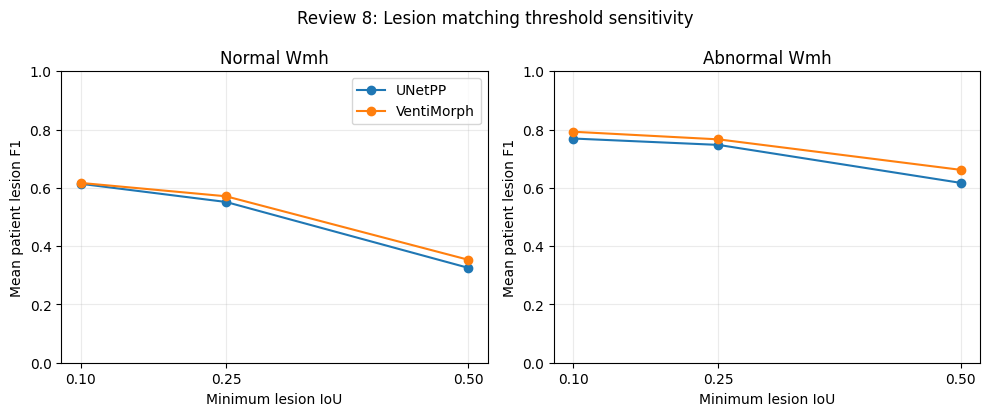

In [9]:
if HAS_GROUND_TRUTH:
    fig,axes=plt.subplots(1,2,figsize=(10,4.2))
    for ax,cls in zip(axes,['normal_wmh','abnormal_wmh']):
        for model in ['UNetPP','VentiMorph']:
            sub=lesion_summary[(lesion_summary.model==model)&(lesion_summary.class_name==cls)].sort_values('iou_threshold')
            ax.plot(sub.iou_threshold,sub.mean_lesion_f1,marker='o',label=model)
        ax.set_title(cls.replace('_',' ').title())
        ax.set_xlabel('Minimum lesion IoU')
        ax.set_ylabel('Mean patient lesion F1')
        ax.set_xticks([.10,.25,.50])
        ax.set_ylim(0,1)
        ax.grid(alpha=.25)
    axes[0].legend()
    fig.suptitle('Review 8: Lesion matching threshold sensitivity')
    fig.tight_layout()
    for ext in ['png','pdf']:
        fig.savefig(OUTPUT_ROOT/f'Review8_lesion_IoU_sensitivity.{ext}',dpi=300,bbox_inches='tight')
    plt.show()
else:
    print("SKIPPED: requires the original MS3SEG MRI + ground-truth masks. Attach MS3SEG in Kaggle Add Input and rerun.")

In [10]:
# Export all generated outputs, even if the original MRI dataset was not attached.
import shutil
status={
  'result_paths': {k:str(v) for k,v in RESULT_PATHS.items()},
  'original_ms3seg_attached': HAS_GROUND_TRUTH,
  'review8_paired_figure_complete': (OUTPUT_ROOT/'Figure5_Paired_20_Patients.png').is_file(),
  'review4_distance_bands_complete': (OUTPUT_ROOT/'Review4_distance_band_summary.csv').is_file(),
  'review8_lesion_iou_complete': (OUTPUT_ROOT/'Review8_lesion_IoU_summary.csv').is_file(),
}
(OUTPUT_ROOT/'ANALYSIS_STATUS.json').write_text(json.dumps(status,indent=2))
archive=shutil.make_archive(str(OUTPUT_ROOT),'zip',root_dir=OUTPUT_ROOT)
print('DOWNLOAD:',archive)
print('STATUS:',json.dumps(status,indent=2))
if not HAS_GROUND_TRUTH:
    print('NEXT STEP: Attach the original MS3SEG MRI dataset (not a result folder) in Kaggle Add Input and rerun to complete Review 4 and lesion IoU.')

DOWNLOAD: /kaggle/working/VentiMorph_Review4_8.zip
STATUS: {
  "result_paths": {
    "VentiMorph": "/kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_V281_FINAL_LOCKED_TEST_COMPLETE_VISUALIZATION_RESULTS (1)",
    "UNetPP": "/kaggle/input/datasets/saifsamiul/ventimorph-resultu-net-result/MS3SEG_UNETPP_FINAL_LOCKED_TEST_ENSEMBLE_RESULTS"
  },
  "original_ms3seg_attached": true,
  "review8_paired_figure_complete": true,
  "review4_distance_bands_complete": true,
  "review8_lesion_iou_complete": true
}
